# TP2 — Préparer les données sans fuite

**Cours :** Introduction au Machine Learning — 60 h — Licence 3 SDIA
**Enseignante :** Dr. Noulapeu Ngaffo Armielle — ENSPD, Université de Douala
**Durée conseillée :** 2 h · **Barème :** 10 points

---

## Objectifs

- Diagnostiquer manquants, types et échelles.
- Construire un ColumnTransformer complet.
- Ajouter un encodage cyclique.
- Fabriquer et corriger une fuite d'encodage cible.

## Travail demandé

1. Répondre aux 3 questions de la section « À vous ».
2. Rendre le notebook exécuté.

## Mode d'emploi

- Exécuter dans l'ordre ; tout tourne sur CPU en moins d'une minute.
- Les cellules **« À vous »** sont évaluées. Graine fixée.

In [1]:
%matplotlib inline
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
np.random.seed(4112)
print('environnement pret')

environnement pret


## 1. Un jeu de données volontairement imparfait

Jeu **synthétique** construit pour ce TP (graine 4112) : 400 dossiers, comme
un export réel — des trous, du texte, des échelles incompatibles et des
valeurs aberrantes.

In [2]:
rng = np.random.default_rng(4112)
n = 400
revenu = rng.lognormal(10.5, .8, n)
df = pd.DataFrame({
    "moyenne": rng.normal(11.5, 3.2, n).clip(0, 20),
    "absences": rng.poisson(9, n),
    "revenu_parent": revenu,
    "filiere": rng.choice(["informatique", "telecom", "reseaux"], n),
    "heure_inscription": rng.integers(0, 24, n),
})
df.loc[rng.random(n) < .08, "moyenne"] = np.nan
df.loc[rng.random(n) < .26, "revenu_parent"] = np.nan
df.loc[rng.random(n) < .29, "filiere"] = np.nan
# une valeur aberrante de capteur
df.loc[3, "revenu_parent"] = 9_000_000
# etiquette : reussite, liee a la moyenne et aux absences
proba = 1 / (1 + np.exp(-(0.45 * df["moyenne"].fillna(df["moyenne"].median())
                          - 0.12 * df["absences"] - 2.2)))
y = (rng.random(n) < proba).astype(int)
print(df.shape, "| reussite :", y.mean().round(3))
df.head(4)

(400, 5) | reussite : 0.798


,moyenne,absences,revenu_parent,filiere,heure_inscription
0,NaN,8,NaN,informatique,9
1,NaN,5,6.694891e+04,telecom,19
2,9.247961,4,1.074953e+05,telecom,10
3,15.465950,8,9.000000e+06,telecom,16


## 2. Diagnostiquer avant de toucher

In [3]:
print("types :")
print(df.dtypes)
print()
print("valeurs manquantes (%) :")
print((df.isna().mean() * 100).round(1))
print()
print("etendues :")
print((df.max(numeric_only=True) - df.min(numeric_only=True)).round(2))

types :
moyenne              float64
absences               int64
revenu_parent        float64
filiere                  str
heure_inscription      int64
dtype: object

valeurs manquantes (%) :
moyenne               8.5
absences              0.0
revenu_parent        23.2
filiere              29.8
heure_inscription     0.0
dtype: float64

etendues :
moyenne                   17.1
absences                  18.0
revenu_parent        8994970.5
heure_inscription         23.0
dtype: float64


## 3. Découper AVANT toute transformation

In [4]:
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(df, y, test_size=.25, random_state=4112, stratify=y)
print("entrainement :", Xtr.shape, "| test :", Xte.shape)

entrainement : (300, 5) | test : (100, 5)


## 4. Premier pipeline, volontairement naïf

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score

num = ["moyenne", "absences", "revenu_parent"]
cat = ["filiere"]

prepa = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
])
modele = Pipeline([("prepa", prepa), ("clf", LogisticRegression(max_iter=1000))])
modele.fit(Xtr, ytr)
pred = modele.predict(Xte)
print(f"exactitude : {accuracy_score(yte, pred):.3f}")
print(f"rappel     : {recall_score(yte, pred):.3f}")

exactitude : 0.840
rappel     : 0.963


## 5. Ajouter l'encodage cyclique de l'heure

23 h et 0 h sont voisines. On ajoute deux colonnes $\sin$ et $\cos$.

In [6]:
def ajoute_cyclique(X):
    X = X.copy()
    X["h_sin"] = np.sin(2 * np.pi * X["heure_inscription"] / 24)
    X["h_cos"] = np.cos(2 * np.pi * X["heure_inscription"] / 24)
    return X

Xtr2, Xte2 = ajoute_cyclique(Xtr), ajoute_cyclique(Xte)
num2 = num + ["h_sin", "h_cos"]
prepa2 = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num2),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
])
modele2 = Pipeline([("prepa", prepa2), ("clf", LogisticRegression(max_iter=1000))])
modele2.fit(Xtr2, ytr)
print(f"avec cyclique : {accuracy_score(yte, modele2.predict(Xte2)):.3f}")

avec cyclique : 0.840


## 6. Fabriquer une fuite par encodage cible

Variable « agence » à 100 modalités, 2 lignes chacune, étiquette aléatoire.
L'encodage calculé **sur tout le jeu** contient la réponse.

In [7]:
from sklearn.model_selection import KFold, cross_val_score

n2 = 200
agence = np.repeat(np.arange(100), 2)
y2 = rng.integers(0, 2, n2)

# (a) fuite : moyenne de y par agence, calculee sur tout le jeu
moy_totale = np.array([y2[agence == c].mean() for c in agence])
s_fuite = cross_val_score(LogisticRegression(max_iter=1000),
                          moy_totale.reshape(-1, 1), y2,
                          cv=KFold(5, shuffle=True, random_state=4112)).mean()

# (b) propre : encodage recalcule dans chaque pli
kf = KFold(5, shuffle=True, random_state=4112)
enc = np.zeros(n2)
for tr, te in kf.split(agence):
    table = {c: y2[tr][agence[tr] == c].mean() for c in np.unique(agence[tr])}
    defaut = y2[tr].mean()
    enc[te] = [table.get(c, defaut) for c in agence[te]]
s_propre = cross_val_score(LogisticRegression(max_iter=1000),
                           enc.reshape(-1, 1), y2, cv=kf).mean()
print(f"avec fuite : {s_fuite:.3f}")
print(f"propre     : {s_propre:.3f}")
print(f"ecart      : {100*(s_fuite-s_propre):.1f} points")

avec fuite : 0.685
propre     : 0.555
ecart      : 13.0 points


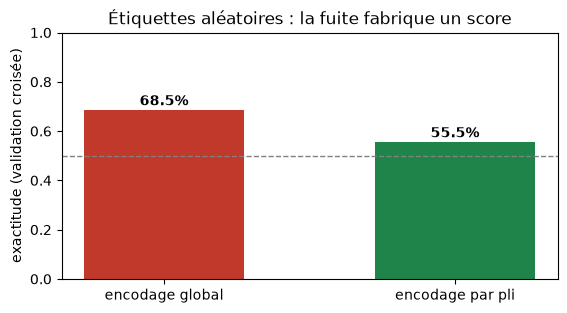

In [8]:
plt.figure(figsize=(6.4, 3.2))
b = plt.bar(["encodage global", "encodage par pli"], [s_fuite, s_propre],
            color=["#C0392B", "#1E8449"], width=.55)
for bb, v in zip(b, [s_fuite, s_propre]):
    plt.text(bb.get_x()+bb.get_width()/2, v+.02, f"{v:.1%}", ha="center", fontweight="bold")
plt.axhline(.5, color="grey", ls="--", lw=1)
plt.ylim(0, 1); plt.ylabel("exactitude (validation croisée)")
plt.title("Étiquettes aléatoires : la fuite fabrique un score")
plt.show()

## 7. À vous (noté)

**1.** Remplacez l'imputation médiane du revenu par une imputation par la
moyenne. Le score change-t-il ? De combien ?

**2.** Retirez la valeur aberrante (`9 000 000`) avant l'entraînement :
le rappel s'améliore-t-il ?

**3.** Dans la section 6, expliquez en deux phrases pourquoi l'encodage global
produit un score élevé alors que l'étiquette est tirée au hasard.

In [9]:
# ---- A VOUS ----
# 1)

# 2)

# 3) reponse :

## 8. Ce qu'il faut retenir

| Geste | Pourquoi |
|---|---|
| diagnostiquer avant de transformer | on ne corrige que ce qu'on a vu |
| découper avant tout | les paramètres de prétraitement ne doivent pas voir le test |
| `ColumnTransformer` | chaque type de colonne a son traitement |
| encodage par pli | sinon la cible fuit dans la variable |